# 7장 멤버십 질의 합성

멤버십 질의 합성(membership query synthesis)은 풀에서 고르지 않고 질의할 샘플을 직접 만든다. 텍스트 분류에서 합성 질의를 세 수준(특징 벡터 보간, 규칙 기반 문장 변형, 마스크 언어 모델 채우기)으로 만들고 판독 가능성과 라벨 보존이 어디서 깨지는지 잰다.

- 7.1 합성 질의의 개념과 역사적 한계
- 7.2 특징 공간 보간 합성
- 7.3 텍스트 변형 기반 합성 — 치환·삭제·순서 교환
- 7.4 마스크 언어 모델 기반 합성
- 7.5 합성 질의의 판독 가능성 문제
- 7.6 풀 기반 질의와의 비교

7.4절이 마스크 언어 모델(klue/roberta-base)을 GPU로 돌리므로 GPU 서버에서 실행했다. 나머지 절은 CPU 연산이다.

### 공통 코드

2장에서 정의한 데이터 읽기, 학생 모델, 시뮬레이션 오라클, 루프, 지표 함수를 그대로 다시 싣는다. 노트북마다 필요한 코드를 모두 담는 규칙을 따른다.

In [1]:
# ── 환경 설정과 상수 ────
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import koreanize_matplotlib
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score
from joblib import Parallel, delayed
import scipy.sparse as sp

SEEDS = [0, 1, 2, 3, 4]
N_INIT, K, BUDGET = 100, 50, 2000
ACCENT, INK, GRAY, GRAY2 = "#E32C24", "#1C1C1A", "#575753", "#8C8A85"
LABEL = {"acc": "정확도", "f1": "매크로 F1"}

# ── 데이터 읽기와 특징 추출 ────
def load_data(name):
    pool = pd.read_csv(f"data/{name}_pool.csv")
    test = pd.read_csv(f"data/{name}_test.csv")
    vec = TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 4), min_df=2,
                          max_features=50000, sublinear_tf=True)
    X_pool = vec.fit_transform(pool.text)          # 라벨을 쓰지 않으므로 누수가 아니다
    vec.stop_words_ = None                         # 잘린 n-gram 목록은 변환에 쓰지 않는다. 병렬 실행 때 복사량을 줄인다
    return dict(name=name, texts=pool.text.values, X_pool=X_pool, y_pool=pool.label.values, vec=vec,
                X_test=vec.transform(test.text), y_test=test.label.values,
                n_classes=pool.label.nunique())

DATA = {name: load_data(name) for name in ("nsmc", "ynat")}
for d in DATA.values():
    print(d["name"], "풀", d["X_pool"].shape, "시험", d["X_test"].shape, "클래스", d["n_classes"])

# ── 학생 모델 ────
def train_model(X, y, seed):
    return LogisticRegression(C=10.0, max_iter=1000, random_state=seed).fit(X, y)

def proba(model, X, n_classes):
    # 라벨 집합에 없는 클래스의 확률 열을 0으로 채워 열 수를 고정한다
    P = np.zeros((X.shape[0], n_classes))
    P[:, model.classes_] = model.predict_proba(X)
    return P

# ── 시뮬레이션 오라클 ────
def make_sim_oracle(y_true):
    # 정답 라벨과 신뢰도 1.0을 돌려준다. 13장의 Jev 오라클이 같은 자리에 들어온다
    return lambda idx, texts: (y_true[idx], np.ones(len(idx)))

# ── 능동 학습 루프 ────
def run_loop(query_fn, oracle_fn, data, seed, n_init=N_INIT, k=K, budget=BUDGET):
    rng = np.random.default_rng(seed)
    n = data["X_pool"].shape[0]
    idx_l = rng.choice(n, n_init, replace=False)
    y_l, _ = oracle_fn(idx_l, data["texts"][idx_l])
    idx_u = np.setdiff1d(np.arange(n), idx_l)
    log = []
    while True:
        model = train_model(data["X_pool"][idx_l], y_l, seed)                          # 1. train
        y_hat = model.predict(data["X_test"])                                             # 평가
        log.append(dict(seed=seed, n_labeled=len(idx_l), acc=accuracy_score(data["y_test"], y_hat),
                        f1=f1_score(data["y_test"], y_hat, average="macro"), t_query=np.nan))
        if len(idx_l) >= budget:
            break
        t0 = time.perf_counter()
        q = query_fn(model, data, idx_l, y_l, idx_u, min(k, budget - len(idx_l)), rng)   # 2. predict · 3. query
        log[-1]["t_query"] = time.perf_counter() - t0
        y_q, _ = oracle_fn(q, data["texts"][q])                                           # 4. label
        idx_l, y_l = np.r_[idx_l, q], np.r_[y_l, y_q]                                     # 5. update
        idx_u = np.setdiff1d(idx_u, q)
    return pd.DataFrame(log), idx_l

# ── 무작위 질의 함수 ────
def query_random(model, data, idx_l, y_l, idx_u, k, rng):
    return rng.choice(idx_u, k, replace=False)

# ── 지표와 실험 도구 ────
def alc(n, m, budget=BUDGET):
    # 라벨 수를 [n0, budget] → [0, 1]로 정규화한 사다리꼴 적분. n0은 첫 측정점이다
    keep = n <= budget
    u, m = (n[keep] - n[0]) / (budget - n[0]), m[keep]
    return np.sum(np.diff(u) * (m[1:] + m[:-1]) / 2)

def label_efficiency(n, m, m_target, budget=BUDGET):
    hit = n[m >= m_target]
    return budget / hit[0] if len(hit) else np.nan

def run_strategies(strategies, data, seeds=SEEDS, n_jobs=-1, **kw):
    # (전략, 시드) 조합을 CPU 코어에 나눠 돌린다. 시드마다 난수 생성기가 따로라 순차 실행과 결과가 같다
    oracle = make_sim_oracle(data["y_pool"])
    jobs = [(name, s) for name in strategies for s in seeds]
    out = Parallel(n_jobs=n_jobs)(delayed(run_loop)(strategies[name], oracle, data, s, **kw) for name, s in jobs)
    print(f"{data['name']:5s} {', '.join(strategies)} 완료")
    return pd.concat([df.assign(strategy=name) for (name, _), (df, _) in zip(jobs, out)], ignore_index=True)

def summarize(res, metric="f1", ref="Random", budget=BUDGET):
    target = res[res.strategy == ref].groupby("n_labeled")[metric].mean().loc[budget]
    rows = []
    for name, g in res.groupby("strategy", sort=False):
        alcs = [alc(d.n_labeled.values, d[metric].values, budget) for _, d in g.groupby("seed")]
        curve = g.groupby("n_labeled")[metric].mean()
        rows.append(dict(strategy=name, ALC=np.mean(alcs), ALC_std=np.std(alcs), final=curve.loc[budget],
                         LE=label_efficiency(curve.index.values, curve.values, target, budget),
                         t_query=g[g.n_labeled < budget].t_query.mean()))
    return pd.DataFrame(rows).round(4)

STYLES = [(ACCENT, "-"), (INK, "--"), (GRAY, "-."), (GRAY2, ":"), ("#2B6CB0", "-"), ("#9C6B30", "--")]

def plot_curves(res, metric, ax, title):
    for (name, g), (c, ls) in zip(res.groupby("strategy", sort=False), STYLES):
        s = g.groupby("n_labeled")[metric].agg(["mean", "std"]).fillna(0)
        ax.plot(s.index, s["mean"], color=c, ls=ls, lw=1.6, label=name)
        ax.fill_between(s.index, s["mean"] - s["std"], s["mean"] + s["std"], color=c, alpha=0.12)
    ax.set(title=title, xlabel="라벨 수", ylabel=LABEL[metric])
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8)

nsmc 풀 (20000, 50000) 시험 (10000, 50000) 클래스 2
ynat 풀 (20000, 50000) 시험 (9107, 50000) 클래스 7


3장의 엔트로피 질의를 다시 싣는다. 합성 전략도 엔트로피로 원천 샘플을 고르고 엔트로피로 변형을 고른다.

In [2]:
def score_entropy(P):
    return -(P * np.log(P + 1e-12)).sum(1)

def make_score_query(score_fn):
    def query_fn(model, data, idx_l, y_l, idx_u, k, rng):
        P = proba(model, data["X_pool"][idx_u], data["n_classes"])
        return idx_u[np.argsort(-score_fn(P))[:k]]
    return query_fn

query_entropy = make_score_query(score_entropy)

## 7.1 합성 질의의 개념과 역사적 한계

풀 기반 질의는 풀 안에서 고르고 합성 질의는 입력 공간 전체에서 고른다. 문제는 합성한 샘플에 라벨을 붙일 오라클이다. 데이터셋 정답은 풀 샘플에만 있으므로 이 장은 풀 20,000개의 정답 전부로 학습한 같은 TF-IDF·로지스틱 회귀를 교사 오라클(teacher oracle)로 둔다. 교사는 정답이 아니라 잘 학습한 모델의 판단이라 잡음이 섞인다. 18장에서 Jev가 이 자리를 대신한다.

In [3]:
# ── 교사 오라클 ────
TEACHER = {}
for name, d in DATA.items():
    TEACHER[name] = train_model(d["X_pool"], d["y_pool"], 0)
    yt = TEACHER[name].predict(d["X_test"])
    print(f"{name} 교사 시험 정확도 {accuracy_score(d['y_test'], yt):.4f} 매크로 F1 {f1_score(d['y_test'], yt, average='macro'):.4f}"
          f" | 풀 정답과의 일치율 {(TEACHER[name].predict(d['X_pool']) == d['y_pool']).mean():.4f}")

def make_teacher_oracle(teacher, data):
    # 합성 샘플은 원문이 없을 수도 있으므로 특징 행으로 판단한다. 신뢰도는 교사의 최대 확률이다
    def oracle_fn(idx, texts):
        P = teacher.predict_proba(data["X_pool"][idx])
        return teacher.classes_[P.argmax(1)], P.max(1)
    return oracle_fn

nsmc 교사 시험 정확도 0.8352 매크로 F1 0.8352 | 풀 정답과의 일치율 0.9567


ynat 교사 시험 정확도 0.7876 매크로 F1 0.7866 | 풀 정답과의 일치율 0.9955


합성 질의 함수는 2장 시그니처를 지킨다. 만든 샘플의 특징 행과 원문을 `data["X_pool"]`, `data["texts"]` 뒤에 덧붙이고 새 인덱스를 돌려준다. run_loop는 처음에 정한 풀 크기로 `idx_u` 를 만들므로 합성 샘플은 라벨 없는 풀에 들어가지 않는다. 실행마다 데이터 묶음을 얕게 복사해 합성 샘플이 다른 실행으로 새지 않게 한다.

In [4]:
# ── 확장 풀과 실행 도구 ────
def append_samples(data, X_new, texts_new):
    n = data["X_pool"].shape[0]
    data["X_pool"] = sp.vstack([data["X_pool"], X_new]).tocsr()
    data["texts"] = np.r_[data["texts"], np.asarray(texts_new, dtype=object)]
    return np.arange(n, n + X_new.shape[0])

ORACLES = {"정답": lambda dd: make_sim_oracle(dd["y_pool"]),
           "교사": lambda dd: make_teacher_oracle(TEACHER[dd["name"]], dd)}

def run_one(query_fn, oracle_name, d, seed):
    dd = dict(d)                                     # 합성 샘플은 이 복사본에만 쌓인다
    return run_loop(query_fn, ORACLES[oracle_name](dd), dd, seed)[0]

def run_synth(specs, d, seeds=SEEDS, n_jobs=-1):
    # specs: {전략 이름: (질의 함수, 오라클 이름)}
    jobs = [(name, s) for name in specs for s in seeds]
    out = Parallel(n_jobs=n_jobs)(delayed(run_one)(*specs[name], d, s) for name, s in jobs)
    print(f"{d['name']:5s} {', '.join(specs)} 완료")
    return pd.concat([df.assign(strategy=name) for (name, _), df in zip(jobs, out)], ignore_index=True)

## 7.2 특징 공간 보간 합성

라벨 샘플 가운데 엔트로피가 큰 k개를 앵커로 잡고 앵커마다 예측 클래스가 다른 라벨 샘플 중 가장 가까운 것을 짝으로 고른다. 두 벡터를 잇는 선분 위에서 학생 모델의 두 클래스 확률이 같아지는 점을 이분법으로 찾아 질의한다. 결과는 원문이 없는 TF-IDF 벡터다. 같은 보간점에 가장 가까운 실제 풀 샘플로 바꿔 정답 오라클에 묻는 변형도 함께 둔다.

In [5]:
# ── 보간 합성 질의 ────
def boundary_points(model, Xa, Xb, ca, cb, iters=20):
    lo, hi = np.zeros(Xa.shape[0]), np.ones(Xa.shape[0])
    col = {c: i for i, c in enumerate(model.classes_)}
    ia, ib = np.array([col[c] for c in ca]), np.array([col[c] for c in cb])
    rows = np.arange(Xa.shape[0])
    for _ in range(iters):
        lam = (lo + hi) / 2
        P = model.predict_proba(sp.diags(1 - lam) @ Xa + sp.diags(lam) @ Xb)
        a_wins = P[rows, ia] > P[rows, ib]
        lo, hi = np.where(a_wins, lam, lo), np.where(a_wins, hi, lam)
    lam = (lo + hi) / 2
    return (sp.diags(1 - lam) @ Xa + sp.diags(lam) @ Xb).tocsr()

def interp_points(model, data, idx_l, k):
    X = data["X_pool"][idx_l]
    P = model.predict_proba(X)
    pred = model.classes_[P.argmax(1)]
    anchors = np.argsort(-score_entropy(P))[:k]
    S = (X[anchors] @ X.T).toarray()
    S[pred[anchors][:, None] == pred[None, :]] = -1      # 예측 클래스가 같은 짝은 뺀다
    mates = S.argmax(1)
    return boundary_points(model, X[anchors], X[mates], pred[anchors], pred[mates])

def query_interp(model, data, idx_l, y_l, idx_u, k, rng):
    return append_samples(data, interp_points(model, data, idx_l, k), [""] * k)

def query_interp_nn(model, data, idx_l, y_l, idx_u, k, rng):
    S = (data["X_pool"][idx_u] @ interp_points(model, data, idx_l, k).T).toarray()
    pick = []
    for j in range(k):                                   # 보간점마다 아직 고르지 않은 가장 가까운 실샘플
        S[pick, :] = -1
        pick.append(int(S[:, j].argmax()))
    return idx_u[np.array(pick)]

## 7.3 텍스트 변형 기반 합성 — 치환·삭제·순서 교환

엔트로피 상위 풀 문장 k개를 원천으로 잡고 원천마다 연산 하나를 적용한 변형 8개를 만든다. 연산은 어절 삭제, 인접 어절 교환, 다른 풀 문장의 어절로 치환 셋이다. 변형 가운데 학생 모델의 엔트로피가 가장 큰 것을 질의한다. 원천 문장은 라벨 없이 풀에 남는다.

In [6]:
# ── 규칙 변형 생성기 ────
def op_delete(w, i, rng, donors):
    return (w[:i] + w[i + 1:]) or w

def op_swap(w, i, rng, donors):
    w, j = list(w), min(i + 1, len(w) - 1)
    w[i], w[j] = w[j], w[i]
    return w

def op_replace(w, i, rng, donors):
    w = list(w)
    w[i] = donors[rng.integers(len(donors))]
    return w

OPS = [op_delete, op_swap, op_replace]
DONORS = {name: np.array(" ".join(d["texts"]).split()) for name, d in DATA.items()}

def rule_variants(texts, rng, donors, m=8):
    out = []
    for t in texts:
        w = t.split()
        out.append([" ".join(OPS[rng.integers(3)](w, int(rng.integers(len(w))), rng, donors)) for _ in range(m)])
    return out

rng = np.random.default_rng(0)
for name, d in DATA.items():
    for t, vs in zip(d["texts"][:2], rule_variants(d["texts"][:2], rng, DONORS[name], m=3)):
        print(f"{name} 원문: {t}")
        for v in vs:
            print("   변형:", v)

nsmc 원문: 1편보단 재밌지만 별로다
   변형: 1편보단 재미없었다. 별로다
   변형: 재밌지만 별로다
   변형: 재밌지만 별로다
nsmc 원문: 영환가?
   변형: 영환가?
   변형: 영환가?
   변형: 이거하길래
ynat 원문: 녹색기술센터 아프리카 기니 가뭄 해결에 나선다
   변형: 녹색기술센터 아프리카 기니 1안타 해결에 나선다
   변형: 녹색기술센터 아프리카 기니 가뭄 공포 나선다
   변형: 녹색기술센터 아프리카 기니 해결에 가뭄 나선다
ynat 원문: 팔레스타인 서안병합 발언 주이스라엘 美대사 ICC 제소 검토
   변형: 팔레스타인 서안병합 결산② 주이스라엘 美대사 ICC 제소 검토
   변형: 1천578억원 서안병합 발언 주이스라엘 美대사 ICC 제소 검토
   변형: 팔레스타인 서안병합 발언 주이스라엘 작년 ICC 제소 검토


In [7]:
# ── 합성 질의 함수 ────
def make_synth_query(gen):
    # gen(원천 문장들, rng, data) -> 원천마다 변형 문장 목록
    def query_fn(model, data, idx_l, y_l, idx_u, k, rng):
        src = idx_u[np.argsort(-score_entropy(proba(model, data["X_pool"][idx_u], data["n_classes"])))[:k]]
        variants = gen(data["texts"][src], rng, data)
        m = len(variants[0])
        Xv = data["vec"].transform([v for vs in variants for v in vs])
        best = score_entropy(proba(model, Xv, data["n_classes"])).reshape(k, m).argmax(1)
        return append_samples(data, Xv[np.arange(k) * m + best], [vs[b] for vs, b in zip(variants, best)])
    return query_fn

query_rule = make_synth_query(lambda texts, rng, data: rule_variants(texts, rng, DONORS[data["name"]]))

## 7.4 마스크 언어 모델 기반 합성

규칙 변형은 문법을 쉽게 깬다. klue/roberta-base의 마스크 언어 모델(masked language model, MLM)로 원천 문장의 어절 15%(최소 하나)를 [MASK]로 가리고 상위 5개 후보 토큰 가운데 하나를 무작위로 골라 채운다. 특수 토큰은 후보에서 뺀다. 고르는 규칙은 7.3절과 같다.

In [8]:
# ── MLM 변형 생성기 ────
import torch
from transformers import AutoTokenizer, AutoModelForMaskedLM, logging as hf_logging
hf_logging.set_verbosity_error()
DEV = "cuda"
mlm_tok = AutoTokenizer.from_pretrained("klue/roberta-base")
mlm = AutoModelForMaskedLM.from_pretrained("klue/roberta-base").to(DEV).eval()
BANNED = torch.tensor(mlm_tok.all_special_ids, device=DEV)
print("torch", torch.__version__, "|", torch.cuda.get_device_name(0))

@torch.no_grad()
def mlm_variants(texts, rng, m=8, rate=0.15, top=5):
    masked = []
    for t in texts:
        w = t.split()
        for _ in range(m):
            ww = list(w)
            for p in rng.choice(len(w), max(1, round(rate * len(w))), replace=False):
                ww[p] = mlm_tok.mask_token
            masked.append(" ".join(ww))
    enc = mlm_tok(masked, return_tensors="pt", padding=True, truncation=True, max_length=64).to(DEV)
    pos = enc.input_ids == mlm_tok.mask_token_id
    logits = mlm.lm_head(mlm.roberta(**enc).last_hidden_state[pos])   # 가린 자리만 어휘 점수를 계산한다
    logits[:, BANNED] = -1e9
    cand = logits.topk(top).indices
    ids = enc.input_ids.clone()
    ids[pos] = cand[torch.arange(len(cand)), torch.as_tensor(rng.integers(top, size=len(cand)), device=DEV)]
    out = mlm_tok.batch_decode(ids, skip_special_tokens=True)
    return [out[i * m:(i + 1) * m] for i in range(len(texts))]

query_mlm = make_synth_query(lambda texts, rng, data: mlm_variants(texts, rng))
rng = np.random.default_rng(0)
for name, d in DATA.items():
    for t, vs in zip(d["texts"][:2], mlm_variants(d["texts"][:2], rng, m=3)):
        print(f"{name} 원문: {t}")
        for v in vs:
            print("   변형:", v)

/home/josh/anaconda3/envs/pytorch/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Loading weights:   0%|          | 0/202 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 202/202 [00:00<00:00, 10699.89it/s]

torch 2.12.0+cu132 | NVIDIA RTX PRO 6000 Blackwell Max-Q Workstation Edition


nsmc 원문: 1편보단 재밌지만 별로다
   변형: 1편보단 재밌지만.
   변형: 1편보단 좀 별로다
   변형: 1편보단 더 별로다
nsmc 원문: 영환가?
   변형: 는
   변형: 는
   변형: 는
ynat 원문: 녹색기술센터 아프리카 기니 가뭄 해결에 나선다
   변형: 녹색기술센터 아프리카 기니 가뭄 퇴치 나선다
   변형: 녹색기술센터 아프리카 기니 빈곤 해결에 나선다
   변형: 녹색기술센터 아프리카 기니 가뭄 해결에 고
ynat 원문: 팔레스타인 서안병합 발언 주이스라엘 美대사 ICC 제소 검토
   변형: 팔레스타인 서안병합 발언 주이스라엘 美 ICC 제소 검토
   변형: 팔레스타인 서안병합 발언 주이스라엘 이스라엘 ICC 제소 검토
   변형: 팔레스타인 서안병합 발언 주이스라엘 美 대사 ICC 제소.


## 7.5 합성 질의의 판독 가능성 문제

합성 방식마다 라벨 보존율과 교사 신뢰도를 잰다. 시드 0에서 무작위 라벨 100개로 학습한 학생 모델로 엔트로피 상위 풀 문장 200개를 원천으로 잡고 방식마다 질의할 변형 하나씩을 만든다. 라벨 보존율은 원천 문장의 정답과 변형에 대한 교사 라벨이 같은 비율이다. 보간점은 원문이 없으므로 가장 가까운 실제 풀 샘플과의 코사인 유사도를 함께 본다.

In [9]:
# ── 라벨 보존과 판독 가능성 ────
keep_rows, examples = [], []
for name, d in DATA.items():
    rng = np.random.default_rng(0)
    idx_l = rng.choice(len(d["y_pool"]), N_INIT, replace=False)
    model = train_model(d["X_pool"][idx_l], d["y_pool"][idx_l], 0)
    idx_u = np.setdiff1d(np.arange(len(d["y_pool"])), idx_l)
    src = idx_u[np.argsort(-score_entropy(proba(model, d["X_pool"][idx_u], d["n_classes"])))[:200]]
    teacher = TEACHER[name]
    for method, gen in (("규칙 변형", lambda t: rule_variants(t, rng, DONORS[name])), ("MLM 변형", lambda t: mlm_variants(t, rng))):
        variants = gen(d["texts"][src])
        Xv = d["vec"].transform([v for vs in variants for v in vs])
        best = score_entropy(proba(model, Xv, d["n_classes"])).reshape(len(src), -1).argmax(1)
        chosen = [vs[b] for vs, b in zip(variants, best)]
        P = teacher.predict_proba(d["vec"].transform(chosen))
        keep_rows.append(dict(data=name, method=method, keep=(P.argmax(1) == d["y_pool"][src]).mean(),
                              conf=P.max(1).mean(), same_as_src=np.mean([c == d["texts"][s] for c, s in zip(chosen, src)])))
        examples += [dict(data=name, method=method, src=d["texts"][s], variant=c, y=d["y_pool"][s], teacher=P[i].argmax())
                     for i, (s, c) in enumerate(zip(src[:4], chosen[:4]))]
    P_src = teacher.predict_proba(d["X_pool"][src])
    keep_rows.append(dict(data=name, method="원천 문장(변형 없음)", keep=(P_src.argmax(1) == d["y_pool"][src]).mean(),
                          conf=P_src.max(1).mean(), same_as_src=1.0))
    Xs = interp_points(model, d, idx_l, 200)
    nn_sim = (Xs @ d["X_pool"][idx_u].T).max(1).toarray().ravel()
    real_sim = (d["X_pool"][src] @ d["X_pool"][idx_u].T).toarray()
    real_sim[real_sim > 0.9999] = 0                      # 자기 자신은 뺀다
    P_int = teacher.predict_proba(Xs)
    keep_rows.append(dict(data=name, method="보간 벡터", keep=np.nan, conf=P_int.max(1).mean(), same_as_src=np.nan))
    print(f"{name} 최근접 실샘플 코사인 — 보간 벡터 평균 {nn_sim.mean():.4f}, 원천 문장 평균 {real_sim.max(1).mean():.4f}")
keep = pd.DataFrame(keep_rows).round(4)
print(keep.to_string(index=False))
print(pd.DataFrame(examples).to_string(index=False))

nsmc 최근접 실샘플 코사인 — 보간 벡터 평균 0.2396, 원천 문장 평균 0.3512


ynat 최근접 실샘플 코사인 — 보간 벡터 평균 0.2686, 원천 문장 평균 0.4062
data       method  keep   conf  same_as_src
nsmc        규칙 변형 0.970 0.8631        0.235
nsmc       MLM 변형 0.885 0.8363        0.070
nsmc 원천 문장(변형 없음) 0.960 0.8626        1.000
nsmc        보간 벡터   NaN 0.7342          NaN
ynat        규칙 변형 0.960 0.8322        0.070
ynat       MLM 변형 0.910 0.8099        0.005
ynat 원천 문장(변형 없음) 1.000 0.8615        1.000
ynat        보간 벡터   NaN 0.5754          NaN
data method                                                                                           src                                                                                       variant  y  teacher
nsmc  규칙 변형                                                                    여자라면 누구나 좋아하고 좋아할수밖에 없는영화.                                                                    여자라면 누구나 좋아할수밖에 좋아하고 없는영화.  1        1
nsmc  규칙 변형                                                                                     투표 꼭 합시다!                       

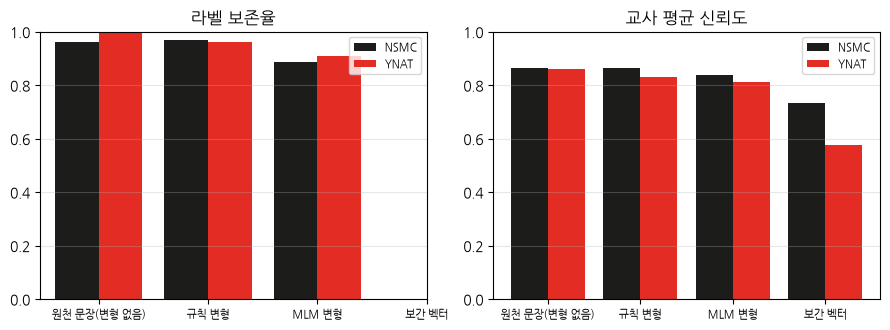

In [10]:
# ── 라벨 보존 그림 ────
fig, axes = plt.subplots(1, 2, figsize=(9, 3.4))
for ax, (col, title) in zip(axes, (("keep", "라벨 보존율"), ("conf", "교사 평균 신뢰도"))):
    t = keep.pivot(index="method", columns="data", values=col).reindex(["원천 문장(변형 없음)", "규칙 변형", "MLM 변형", "보간 벡터"])
    x = np.arange(len(t))
    ax.bar(x - 0.2, t["nsmc"], 0.4, color=INK, label="NSMC")
    ax.bar(x + 0.2, t["ynat"], 0.4, color=ACCENT, label="YNAT")
    ax.set(xticks=x, xticklabels=t.index, title=title, ylim=(0, 1))
    ax.tick_params(axis="x", labelsize=8)
    ax.grid(alpha=0.3, axis="y")
    ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig("out/ch07_label_keep.png", dpi=200)

## 7.6 풀 기반 질의와의 비교

모든 전략을 같은 설정(초기 100, 질의 50, 예산 2,000, 시드 5개)으로 돌린다. 엔트로피를 교사 오라클로 한 번 더 돌려 오라클 차이와 질의 방식 차이를 가른다. MLM 변형은 GPU를 쓰므로 병렬로 돌리지 않고 차례로 돌린다.

In [11]:
# ── 전 전략 비교 ────
CPU_SPECS = {"Random": (query_random, "정답"), "엔트로피": (query_entropy, "정답"), "엔트로피·교사": (query_entropy, "교사"),
             "보간 합성": (query_interp, "교사"), "보간→최근접": (query_interp_nn, "정답"), "규칙 변형": (query_rule, "교사")}
res = {}
for name, d in DATA.items():
    r_cpu = run_synth(CPU_SPECS, d)
    r_mlm = pd.concat([run_one(query_mlm, "교사", d, s).assign(strategy="MLM 변형") for s in SEEDS], ignore_index=True)
    res[name] = pd.concat([r_cpu, r_mlm], ignore_index=True)
    res[name].to_csv(f"results/ch07_{name}.csv", index=False)
    ch03 = pd.read_csv(f"results/ch03_{name}.csv")
    for s in ("Random", "엔트로피"):
        diff = np.abs(ch03[ch03.strategy == s].f1.values - res[name][res[name].strategy == s].f1.values).max()
        print(name, s, "3장 대비 F1 최대 차이:", diff)
    print(f"\n{name} 매크로 F1")
    print(summarize(res[name], "f1").to_string(index=False))

nsmc  Random, 엔트로피, 엔트로피·교사, 보간 합성, 보간→최근접, 규칙 변형 완료


nsmc Random 3장 대비 F1 최대 차이: 0.0031949829369775085
nsmc 엔트로피 3장 대비 F1 최대 차이: 0.06909262754204437

nsmc 매크로 F1
strategy    ALC  ALC_std  final     LE  t_query
  Random 0.7426   0.0033 0.7796 1.0000   0.0000
    엔트로피 0.7476   0.0052 0.7852 1.1765   0.0090
 엔트로피·교사 0.7549   0.0020 0.7919 1.3333   0.0082
   보간 합성 0.6063   0.0453 0.5874    NaN   0.0289
  보간→최근접 0.7235   0.0076 0.7651    NaN   0.0451
   규칙 변형 0.7559   0.0020 0.7948 1.4815   0.0284
  MLM 변형 0.7435   0.0027 0.7774    NaN   0.4633


ynat  Random, 엔트로피, 엔트로피·교사, 보간 합성, 보간→최근접, 규칙 변형 완료


ynat Random 3장 대비 F1 최대 차이: 0.0032926004459508107
ynat 엔트로피 3장 대비 F1 최대 차이: 0.04154542935940375

ynat 매크로 F1
strategy    ALC  ALC_std  final     LE  t_query
  Random 0.5335   0.0070 0.6500 1.0000   0.0001
    엔트로피 0.6122   0.0055 0.7183 1.9048   0.0206
 엔트로피·교사 0.6142   0.0061 0.7184 1.9048   0.0186
   보간 합성 0.2926   0.0291 0.2930    NaN   0.0290
  보간→최근접 0.5288   0.0145 0.6317    NaN   0.0523
   규칙 변형 0.6075   0.0103 0.7095 1.8182   0.0378
  MLM 변형 0.6025   0.0094 0.7062 1.7391   0.2223


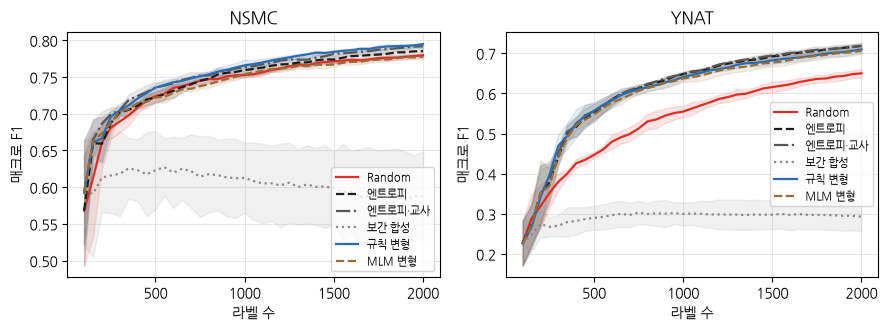

In [12]:
# ── 학습 곡선 ────
fig, axes = plt.subplots(1, 2, figsize=(9, 3.4))
for ax, (name, r) in zip(axes, res.items()):
    plot_curves(r[r.strategy.isin(["엔트로피", "엔트로피·교사", "MLM 변형", "규칙 변형", "보간 합성", "Random"])], "f1", ax, name.upper())
fig.tight_layout()
fig.savefig("out/ch07_curves.png", dpi=200)